# Conncecting Google Drive

In [2]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


# Import Dataset

In [3]:

DATASET_PATH = "/content/drive/MyDrive/ML_Image_Classification_Dataset"


In [4]:

import os

print(os.listdir(DATASET_PATH))


['Daisy', 'Dandelion', 'Rose', 'Sunflower', 'Tulip']


## Know Content of each class

In [5]:

import os

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(f"{class_name}: {len(images)} images")


Daisy: 764 images
Dandelion: 1051 images
Rose: 783 images
Sunflower: 733 images
Tulip: 984 images


### Know addresses to remove duplicated images

In [6]:
import os

tulip_path = os.path.join(DATASET_PATH, "Tulip")

files = sorted(os.listdir(tulip_path))

print("Total files:", len(files))

for file in files:
    print(file)

Total files: 984
100930342_92e8746431_n.jpg
10094729603_eeca3f2cb6.jpg
10094731133_94a942463c.jpg
10128546863_8de70c610d.jpg
10163955604_ae0b830975_n.jpg
10164073235_f29931d91e.jpg
10686568196_b1915544a8.jpg
107693873_86021ac4ea_n.jpg
10791227_7168491604.jpg
10995953955_089572caf0.jpg
110147301_ad921e2828.jpg
112334842_3ecf7585dd.jpg
112428665_d8f3632f36_n.jpg
112428919_f0c5ad7d9d_n.jpg
112650879_82adc2cc04_n.jpg
112651128_7b5d39a346_m.jpg
112951022_4892b1348b_n.jpg
112951086_150a59d499_n.jpg
113291410_1bdc718ed8_n.jpg
113902743_8f537f769b_n.jpg
113960470_38fab8f2fb_m.jpg
11441893003_ab83672800.jpg
11614202956_1dcf1c96a1.jpg
116343334_9cb4acdc57_n.jpg
11746080_963537acdc.jpg
11746276_de3dec8201.jpg
11746367_d23a35b085_n.jpg
11746452_5bc1749a36.jpg
11746548_26b3256922_n.jpg
12024561754_ce9667e4dc_n.jpg
12025038686_7f10811d4b_n.jpg
12025042086_78bafc0eb6_n.jpg
12163418275_bd6a1edd61.jpg
122450705_9885fff3c4_n.jpg
12517756805_56b74be742.jpg
12548574923_5e90f4ceea.jpg
12557176134_ecbf15885

In [7]:
import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for filename in os.listdir(tulip_path):
    path = os.path.join(tulip_path, filename)

    if os.path.isfile(path):
        with open(path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        hashes[file_hash].append(filename)

for group in hashes.values():
    if len(group) > 1:
        print("Duplicates:", group)

In [8]:

import os

duplicate_files = [
    "4395433872_e073d8c721_n (1).jpg",
    "4521037085_70d5802e1d_m (1).jpg",
    "4520582070_d14a14f038 (1).jpg",
    "4522764992_e9d70b82c1_m (1).jpg",
    "4522130258_9ee44cf73f_m (1).jpg",
    "4550091966_7f3e0f8802_n (1).jpg"
]

for filename in duplicate_files:
    file_path = os.path.join(tulip_path, filename)

    if os.path.exists(file_path):
        os.remove(file_path)
        print("Deleted:", filename)

print("Cleanup completed!")


Cleanup completed!


## Connect to github rep.

In [9]:
%cd /content

!git clone https://github.com/abdelhalimyasser/machine-learning-models-2026-fcai-cu.git

/content
Cloning into 'machine-learning-models-2026-fcai-cu'...
remote: Enumerating objects: 4373, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 4373 (delta 7), reused 17 (delta 3), pack-reused 4347 (from 1)
Receiving objects: 100% (4373/4373), 230.55 MiB | 17.20 MiB/s, done.
Resolving deltas: 100% (15/15), done.
Updating files: 100% (4332/4332), done.


In [10]:
%cd /content/machine-learning-models-2026-fcai-cu
!ls

/content/machine-learning-models-2026-fcai-cu
datasets  docs	guidlines  models  notebooks  README.md  requirements.txt


In [11]:
%cd /content/machine-learning-models-2026-fcai-cu/models/b_image_classification

/content/machine-learning-models-2026-fcai-cu/models/b_image_classification


In [12]:
!pwd

/content/machine-learning-models-2026-fcai-cu/models/b_image_classification


In [13]:
%cd /content/machine-learning-models-2026-fcai-cu

/content/machine-learning-models-2026-fcai-cu


In [14]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [15]:
!git add models/b_image_classification/Untitled0.ipynb

In [16]:
%cd /content/machine-learning-models-2026-fcai-cu
!git status

/content/machine-learning-models-2026-fcai-cu
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [17]:
import getpass
import subprocess
import base64

# Reset repository URL without saving the token
subprocess.run([
    "git", "remote", "set-url", "origin",
    "https://github.com/abdelhalimyasser/machine-learning-models-2026-fcai-cu.git"
], check=True)

username = "noureldeenshaaban"
token = getpass.getpass("GitHub Token: ")

auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

result = subprocess.run(
    ["git", "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
     "push", "origin", "main"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

GitHub Token: ··········

Everything up-to-date



In [18]:
%cd /content/machine-learning-models-2026-fcai-cu
!git status

/content/machine-learning-models-2026-fcai-cu
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [19]:
%cd /content/machine-learning-models-2026-fcai-cu
!git status

/content/machine-learning-models-2026-fcai-cu
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


##Data Exploration

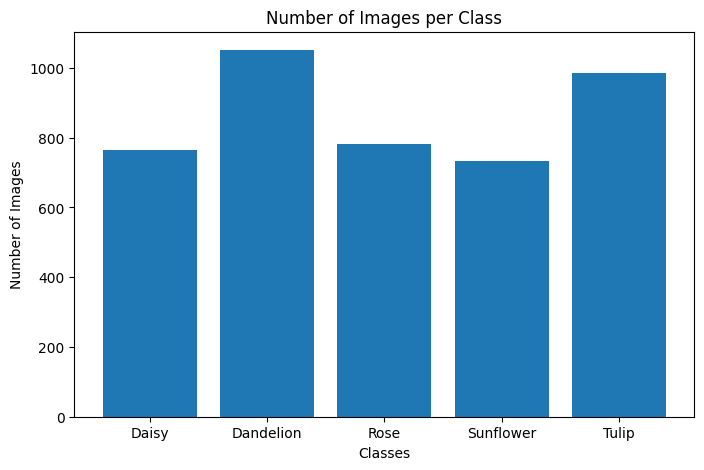

In [20]:
import matplotlib.pyplot as plt

class_counts = {}

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        class_counts[class_name] = len(images)

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())

plt.title("Number of Images per Class")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.show()

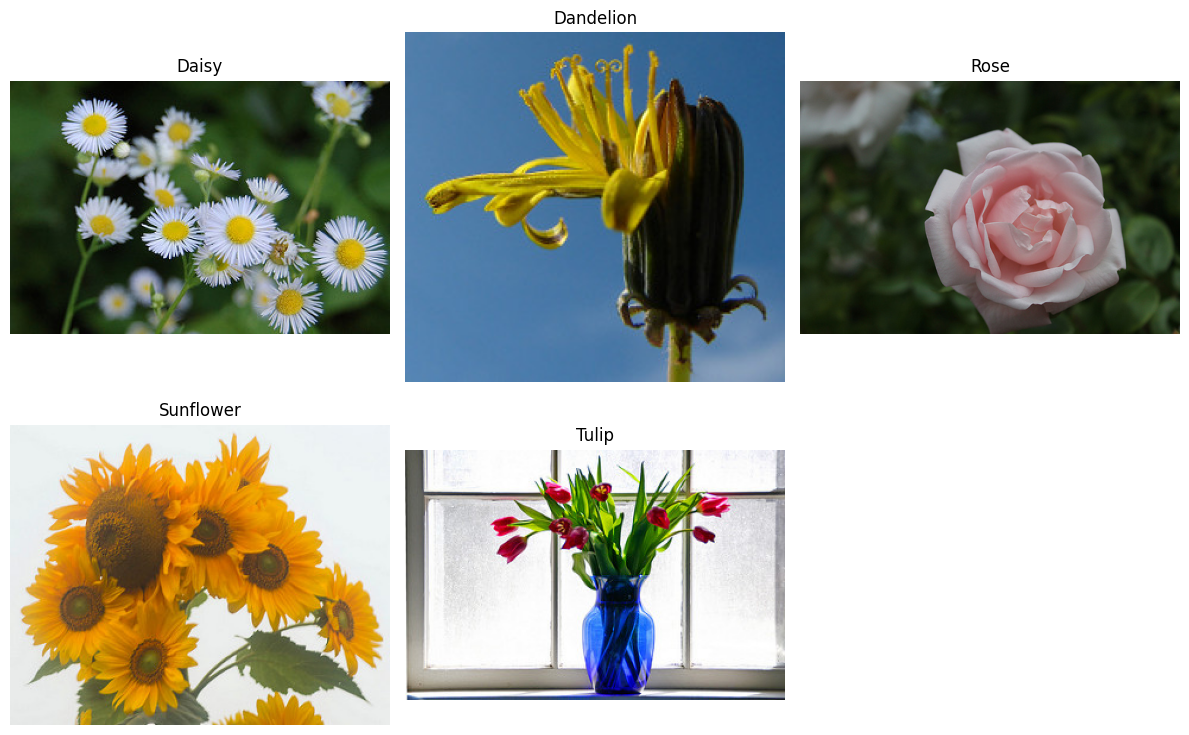

In [21]:
import random
import matplotlib.pyplot as plt
import cv2
import os

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(sorted(os.listdir(DATASET_PATH))):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        img_name = random.choice(images)
        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

## Preprocessing

In [22]:

import os
import cv2
import numpy as np

IMG_SIZE = (128, 128)

X = []
y = []

classes = sorted(os.listdir(DATASET_PATH))

print("Classes:", classes)

for label, class_name in enumerate(classes):

    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for img_name in os.listdir(class_path):

        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)

        if img is None:
            continue

        img = cv2.resize(img, IMG_SIZE)

        img = img.astype(np.float32) / 255.0

        X.append(img)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(classes))


Classes: ['Daisy', 'Dandelion', 'Rose', 'Sunflower', 'Tulip']
X shape: (4315, 128, 128, 3)
y shape: (4315,)
Number of classes: 5


## Flattening

In [23]:

X_flat = X.reshape(X.shape[0], -1)

print("Original shape:", X.shape)
print("Flattened shape:", X_flat.shape)


Original shape: (4315, 128, 128, 3)
Flattened shape: (4315, 49152)


### Train, Validation, and Test Split

In [24]:

from sklearn.model_selection import train_test_split

# Split training data and temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X_flat,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split validation and test data
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (3020, 49152) (3020,)
Validation: (647, 49152) (647,)
Testing: (648, 49152) (648,)


## StandardScaler

In [25]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


Training: (3020, 49152)
Validation: (647, 49152)
Testing: (648, 49152)


## K-Nearest Neighbors (KNN) Classifier

In [26]:

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [27]:

from sklearn.metrics import accuracy_score

k_values = [3, 5, 7, 9]

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    y_val_pred = knn.predict(X_val_scaled)

    accuracy = accuracy_score(y_val, y_val_pred)

    print(f"K = {k}, Validation Accuracy = {accuracy:.4f}")


K = 3, Validation Accuracy = 0.3076
K = 5, Validation Accuracy = 0.3215
K = 7, Validation Accuracy = 0.3060
K = 9, Validation Accuracy = 0.3122


## Best K Selection

In [28]:

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

print("Best KNN model trained successfully!")


Best KNN model trained successfully!


save latest changes to github

In [45]:
%cd /content/machine-learning-models-2026-fcai-cu
!git status --short

/content/machine-learning-models-2026-fcai-cu


In [46]:
import os
import subprocess

repo = "/content/machine-learning-models-2026-fcai-cu"
notebook = os.path.join(repo, "models/b_image_classification/Untitled0.ipynb")

print("========== NOTEBOOK & GIT DIAGNOSIS ==========")

print("\n1. Current working directory:")
print(os.getcwd())

print("\n2. Repository exists:")
print(os.path.exists(repo))

print("\n3. Notebook inside repository:")
print(notebook)
print("Exists:", os.path.exists(notebook))

print("\n4. Git status:")
subprocess.run(["git", "-C", repo, "status", "--short"])

print("\n5. Tracked notebook:")
subprocess.run([
    "git", "-C", repo, "ls-files",
    "models/b_image_classification/Untitled0.ipynb"
])

print("\n6. Notebook file information:")
if os.path.exists(notebook):
    print("Size:", os.path.getsize(notebook), "bytes")
    print("Last modified:", os.path.getmtime(notebook))

print("\n========== END ==========")

========== NOTEBOOK & GIT DIAGNOSIS ==========

1. Current working directory:
/content/machine-learning-models-2026-fcai-cu

2. Repository exists:
True

3. Notebook inside repository:
/content/machine-learning-models-2026-fcai-cu/models/b_image_classification/Untitled0.ipynb
Exists: True

4. Git status:

5. Tracked notebook:

6. Notebook file information:
Size: 54182 bytes
Last modified: 1795202765.0704107

========== END ==========


In [47]:
import subprocess

repo = "/content/machine-learning-models-2026-fcai-cu"
file = "models/b_image_classification/Untitled0.ipynb"

commands = [
    ["git", "-C", repo, "check-ignore", "-v", file],
    ["git", "-C", repo, "status", "--short", "--untracked-files=all"],
    ["git", "-C", repo, "log", "-1", "--oneline"]
]

for cmd in commands:
    print("\n$", " ".join(cmd))
    result = subprocess.run(cmd, capture_output=True, text=True)
    print("Output:", result.stdout or "No output")
    print("Error:", result.stderr or "No error")


$ git -C /content/machine-learning-models-2026-fcai-cu check-ignore -v models/b_image_classification/Untitled0.ipynb
Output: No output
Error: No error

$ git -C /content/machine-learning-models-2026-fcai-cu status --short --untracked-files=all
Output: No output
Error: No error

$ git -C /content/machine-learning-models-2026-fcai-cu log -1 --oneline
Output: 31f6419 preprocessing and EDA

Error: No error


In [48]:
import subprocess

repo = "/content/machine-learning-models-2026-fcai-cu"
file = "models/b_image_classification/Untitled0.ipynb"

commands = {
    "File in latest commit": ["git", "-C", repo, "ls-tree", "-r", "--name-only", "HEAD", file],
    "File in remote branch": ["git", "-C", repo, "ls-tree", "-r", "--name-only", "origin/main", file],
    "Git repository root": ["git", "-C", repo, "rev-parse", "--show-toplevel"],
    "All files in folder": ["ls", "-la", f"{repo}/models/b_image_classification"]
}

for title, cmd in commands.items():
    print(f"\n--- {title} ---")
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout or "No output")
    if result.stderr:
        print("Error:", result.stderr)


--- File in latest commit ---
models/b_image_classification/Untitled0.ipynb


--- File in remote branch ---
models/b_image_classification/Untitled0.ipynb


--- Git repository root ---
/content/machine-learning-models-2026-fcai-cu


--- All files in folder ---
total 64
drwxr-xr-x 2 root root  4096 Nov 20 19:26 .
drwxr-xr-x 5 root root  4096 Nov 20 19:26 ..
-rw-r--r-- 1 root root     0 Nov 20 19:26 .gitignore
-rw-r--r-- 1 root root 54182 Nov 20 19:26 Untitled0.ipynb



In [49]:
import os
import glob

print("========== NOTEBOOK FILES ==========")

for path in glob.glob("/content/**/*.ipynb", recursive=True):
    print(path, "|", os.path.getsize(path), "bytes")

print("\n========== DRIVE NOTEBOOKS ==========")

for path in glob.glob("/content/drive/MyDrive/**/*.ipynb", recursive=True):
    if "Untitled0" in path:
        print(path, "|", os.path.getsize(path), "bytes")

========== NOTEBOOK FILES ==========
/content/machine-learning-models-2026-fcai-cu/notebooks/c_text_classification/data_preprocessing.ipynb | 21292 bytes
/content/machine-learning-models-2026-fcai-cu/notebooks/a_numerical_regression/regression.ipynb | 72801 bytes
/content/machine-learning-models-2026-fcai-cu/models/b_image_classification/Untitled0.ipynb | 54182 bytes
/content/drive/MyDrive/Colab Notebooks/Flowers_Image_Classification.ipynb | 2636 bytes
/content/drive/MyDrive/Colab Notebooks/Part_B_Image_Classification.ipynb | 7326 bytes
/content/drive/MyDrive/Colab Notebooks/Copy of Untitled0.ipynb | 40068 bytes
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb | 1172009 bytes

========== DRIVE NOTEBOOKS ==========
/content/drive/MyDrive/Colab Notebooks/Copy of Untitled0.ipynb | 40068 bytes
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb | 1172009 bytes


In [50]:
import json
import os

files = {
    "GitHub": "/content/machine-learning-models-2026-fcai-cu/models/b_image_classification/Untitled0.ipynb",
    "Drive_Untitled": "/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb",
    "Drive_Copy": "/content/drive/MyDrive/Colab Notebooks/Copy of Untitled0.ipynb"
}

for name, path in files.items():
    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])
    code_cells = [c for c in cells if c["cell_type"] == "code"]

    print(f"\n===== {name} =====")
    print("Total cells:", len(cells))
    print("Code cells:", len(code_cells))
    print("Last 5 code cells:")

    for cell in code_cells[-5:]:
        source = "".join(cell["source"])
        print(source[:250].replace("\n", " "))


===== GitHub =====
Total cells: 11
Code cells: 11
Last 5 code cells:
 import os  duplicate_files = [     "4395433872_e073d8c721_n (1).jpg",     "4521037085_70d5802e1d_m (1).jpg",     "4520582070_d14a14f038 (1).jpg",     "4522764992_e9d70b82c1_m (1).jpg",     "4522130258_9ee44cf73f_m (1).jpg",     "4550091966_7f3e0f880
%cd /content  !git clone https://github.com/abdelhalimyasser/machine-learning-models-2026-fcai-cu.git
%cd /content/machine-learning-models-2026-fcai-cu !ls
%cd /content/machine-learning-models-2026-fcai-cu/models/b_image_classification
!pwd

===== Drive_Untitled =====
Total cells: 45
Code cells: 32
Last 5 code cells:
%cd /content/machine-learning-models-2026-fcai-cu !git status --short
import os import subprocess  repo = "/content/machine-learning-models-2026-fcai-cu" notebook = os.path.join(repo, "models/b_image_classification/Untitled0.ipynb")  print("========== NOTEBOOK & GIT DIAGNOSIS ==========")  print("\n1. Current working d
import subprocess  repo = "/content/mac